# GRN 4: Covariate-shift stress test on gene-regulatory-network data

This notebook uses the **prepared GRN pair datasets** from Notebook 01 (SERGIO) and/or Notebook 02 (DREAM5). It does **not** use the Track 1 one-dimensional synthetic classification problem.

For each dataset, a Transformer is trained on the source training pairs and evaluated on (1) the ordinary held-out GRN pairs and (2) the same held-out pairs after a controlled affine shift of the two expression channels. The pair labels remain unchanged. This is a **controlled feature-distribution stress test**: it measures sensitivity to expression-scale/offset changes, but it does not prove that real-world deployment shift is pure covariate shift or that the true conditional label mechanism is invariant under arbitrary transformations.

The primary comparison uses BCE training with `lambda=1.0` (predictive-only) and end-to-end calibration-aware training with `lambda=0.5` and `lambda=0.1`, for small and medium Transformers. Temperature scaling and isotonic regression are fitted on validation predictions from the predictive-only model and then evaluated on both test distributions. Since real GRN labels do not provide a known posterior, this notebook does **not** report posterior MSE or other metrics requiring the true posterior.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive/', force_remount=True)
    PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/"
    if not os.path.isdir(PROJECT_DIR):
        PROJECT_DIR = os.getcwd()
except ImportError:
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)
from grn_experiment_utils import (
    split_indices, train_model, predict, evaluate,
    fit_temperature, apply_temperature, fit_isotonic, apply_isotonic
)

data_dir = os.path.join(PROJECT_DIR, "data")
os.makedirs(data_dir, exist_ok=True)
available = [f for f in ["sergio_pair_data.npz", "dream5_net1_pair_data.npz"]
             if os.path.exists(os.path.join(data_dir, f))]
print("Project directory:", PROJECT_DIR)
print("GRN pair datasets found:", available)
if not available:
    raise FileNotFoundError(
        "No prepared GRN pair data found. Run Notebook 01 and/or Notebook 02 first; "
        "expected sergio_pair_data.npz and/or dream5_net1_pair_data.npz in data/."
    )

SEEDS = [42, 123, 2026]
ARCHITECTURES = ["small", "medium"]
LAMBDAS = [1.0, 0.5, 0.1]
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
PATIENCE = 5

# Controlled affine shift applied only to the held-out test inputs.
# Channel 0 = regulator expression; channel 1 = target expression.
TF_SCALE, TF_OFFSET = 1.5, 0.5
TARGET_SCALE, TARGET_OFFSET = 0.75, -0.25

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

Mounted at /content/drive/
Project directory: /content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/
GRN pair datasets found: ['sergio_pair_data.npz', 'dream5_net1_pair_data.npz']


## 1. Define the GRN feature-distribution shift

The input tensor has shape `(candidate_pairs, conditions, 2)`, where the two channels are regulator and target expression. The shifted test version applies fixed affine transformations to these channels. This changes the observed feature distribution while retaining each candidate pair's binary ground-truth label. It is intentionally a stress test, not a claim that a real biological shift is always affine.

In [2]:
def shift_expression_features(X):
    """Apply a fixed, invertible channel-wise affine shift to GRN pair inputs."""
    X_shift = np.asarray(X, dtype=np.float32).copy()
    if X_shift.ndim != 3 or X_shift.shape[-1] != 2:
        raise ValueError(f"Expected X with shape (pairs, conditions, 2); got {X_shift.shape}")
    X_shift[..., 0] = TF_SCALE * X_shift[..., 0] + TF_OFFSET
    X_shift[..., 1] = TARGET_SCALE * X_shift[..., 1] + TARGET_OFFSET
    return X_shift


def calibration_in_large(y, p):
    """Absolute difference between mean predicted probability and observed prevalence."""
    return float(abs(np.mean(p) - np.mean(y)))


def evaluate_grn_split(y, p):
    metrics = evaluate(y, p)
    metrics["calibration_in_large"] = calibration_in_large(y, p)
    return metrics

# Show that the shift changes the input marginals.
for filename in available:
    d = np.load(os.path.join(data_dir, filename), allow_pickle=True)
    X = d["X"].astype("float32")
    Xs = shift_expression_features(X)
    print(f"{filename}: X={X.shape}; channel means source={X.mean(axis=(0,1)).round(3)}, "
          f"shifted={Xs.mean(axis=(0,1)).round(3)}")


sergio_pair_data.npz: X=(5000, 64, 2); channel means source=[-0. -0.], shifted=[ 0.5  -0.25]
dream5_net1_pair_data.npz: X=(12000, 64, 2); channel means source=[0.004 0.008], shifted=[ 0.505 -0.244]


## 2. Multi-seed experiment

Each seed defines a stratified train/validation/test split. Models are trained on the unshifted training inputs; early stopping uses the unshifted validation set. We evaluate the same held-out pairs under both the original and shifted inputs. Post-hoc calibrators are fit on validation predictions only. The labels are never changed by the feature transformation.

In [3]:
start_time = time.time()
rows = []

for filename in available:
    d = np.load(os.path.join(data_dir, filename), allow_pickle=True)
    X = d["X"].astype("float32")
    y = d["y"].astype("float32")
    X_shift = shift_expression_features(X)
    dataset = filename.replace("_pair_data.npz", "")
    print(f"\n{dataset}: X={X.shape}; positives={int(y.sum())}/{len(y)}")

    for seed in SEEDS:
        tr, va, te = split_indices(y, seed=seed)
        for architecture in ARCHITECTURES:
            # Fit predictive-only BCE model once; calibrators use its validation predictions.
            model_base, _ = train_model(
                X, y, tr, va, lam=1.0, base_loss="bce", model_size=architecture,
                epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE,
                seed=seed, patience=PATIENCE
            )
            p_val_base = predict(model_base, X[va])
            T = fit_temperature(y[va], p_val_base)
            iso = fit_isotonic(y[va], p_val_base)

            method_predictions = {
                "predictive_only": (predict(model_base, X[te]), predict(model_base, X_shift[te])),
                "temperature_scaling": (
                    apply_temperature(predict(model_base, X[te]), T),
                    apply_temperature(predict(model_base, X_shift[te]), T)
                ),
                "isotonic_regression": (
                    apply_isotonic(predict(model_base, X[te]), iso),
                    apply_isotonic(predict(model_base, X_shift[te]), iso)
                ),
            }

            for lam in [0.5, 0.1]:
                model_cal, _ = train_model(
                    X, y, tr, va, lam=lam, base_loss="bce", model_size=architecture,
                    epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE,
                    seed=seed, patience=PATIENCE
                )
                method_predictions[f"end_to_end_lambda_{lam:g}"] = (
                    predict(model_cal, X[te]), predict(model_cal, X_shift[te])
                )

            y_test = y[te].astype(int)
            for method, (p_id, p_shift) in method_predictions.items():
                for split, p in [("in_distribution", p_id), ("shifted_features", p_shift)]:
                    row = {
                        "dataset": dataset, "seed": seed, "architecture": architecture,
                        "method": method, "split": split,
                        "temperature": T if method == "temperature_scaling" else np.nan,
                        "n_test": len(te), "positive_rate": float(y_test.mean())
                    }
                    row.update(evaluate_grn_split(y_test, p))
                    rows.append(row)
        print(f"  completed seed {seed}")

results_df = pd.DataFrame(rows)
metric_cols = ["AUROC", "AUPR", "Brier", "ECE10", "calibration_in_large"]
summary_df = (
    results_df.groupby(["dataset", "architecture", "method", "split"])[metric_cols]
    .agg(["mean", "std"]).round(4)
)
display(summary_df)
results_df.to_csv(os.path.join(data_dir, "grn4_covariate_shift_results.csv"), index=False)
summary_df.to_csv(os.path.join(data_dir, "grn4_covariate_shift_summary.csv"))

results_df.to_excel(os.path.join(data_dir, "grn4_covariate_shift_results.xlsx"), index=False)
summary_df.to_excel(os.path.join(data_dir, "grn4_covariate_shift_summary.xlsx"))

print(f"Saved results. Elapsed: {(time.time()-start_time)/60:.1f} min")


sergio: X=(5000, 64, 2); positives=303/5000


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 42


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 123


...

  completed seed 123


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 2026


AUROC  \
                                                                   mean   
dataset     architecture method                split                      
dream5_net1 medium       end_to_end_lambda_0.1 in_distribution   0.8281   
                                               shifted_features  0.6989   
                         end_to_end_lambda_0.5 in_distribution   0.8758   
                                               shifted_features  0.7607   
                         isotonic_regression   in_distribution   0.8578   
                                               shifted_features  0.7529   
                         predictive_only       in_distribution   0.8592   
                                               shifted_features  0.7570   
                         temperature_scaling   in_distribution   0.8592   
                                               shifted_features  0.7570   
            small        end_to_end_lambda_0.1 in_distribution   0.7899   
                                               shifted_features  0.6892   
                         end_to_end_lambda_0.5 in_distribution   0.8168   
                                               shifted_features  0.7278   
                         isotonic_regression   in_distribution   0.8318   
                                               shifted_features  0.7227   
                         predictive_only       in_distribution   0.8336   
                                               shifted_features  0.7299   
                         temperature_scaling   in_distribution   0.8336   
                                               shifted_features  0.7299   
sergio      medium       end_to_end_lambda_0.1 in_distribution   0.5902   
                                               shifted_features  0.5878   
                         end_to_end_lambda_0.5 in_distribution   0.6208   
                                               shifted_features  0.6111   
                         isotonic_regression   in_distribution   0.6158   
                                               shifted_features  0.6277   
                         predictive_only       in_distribution   0.6296   
                                               shifted_features  0.6221   
                         temperature_scaling   in_distribution   0.6296   
                                               shifted_features  0.6221   
            small        end_to_end_lambda_0.1 in_distribution   0.6139   
                                               shifted_features  0.6071   
                         end_to_end_lambda_0.5 in_distribution   0.6223   
                                               shifted_features  0.6185   
                         isotonic_regression   in_distribution   0.6196   
                                               shifted_features  0.5889   
                         predictive_only       in_distribution   0.6201   
                                               shifted_features  0.6137   
                         temperature_scaling   in_distribution   0.6201   
                                               shifted_features  0.6137   

                                                                         \
                                                                    std   
dataset     architecture method                split                      
dream5_net1 medium       end_to_end_lambda_0.1 in_distribution   0.0123   
                                               shifted_features  0.0479   
                         end_to_end_lambda_0.5 in_distribution   0.0311   
                                               shifted_features  0.0324   
                         isotonic_regression   in_distribution   0.0379   
                                               shifted_features  0.0301   
                         predictive_only       in_distribution   0.0373   
                                               shifted_features  0.0308   
               

Saved results. Elapsed: 6.7 min


## 3. Visual comparison

The plots show mean and standard deviation across the three seeds. Lower ECE/Brier/calibration-in-the-large and higher AUROC/AUPR are generally preferred, but calibration metrics can be sensitive to the candidate-pair sampling scheme. The positive prevalence is the same between the in-distribution and shifted-feature test sets because the same test pairs and labels are reused.

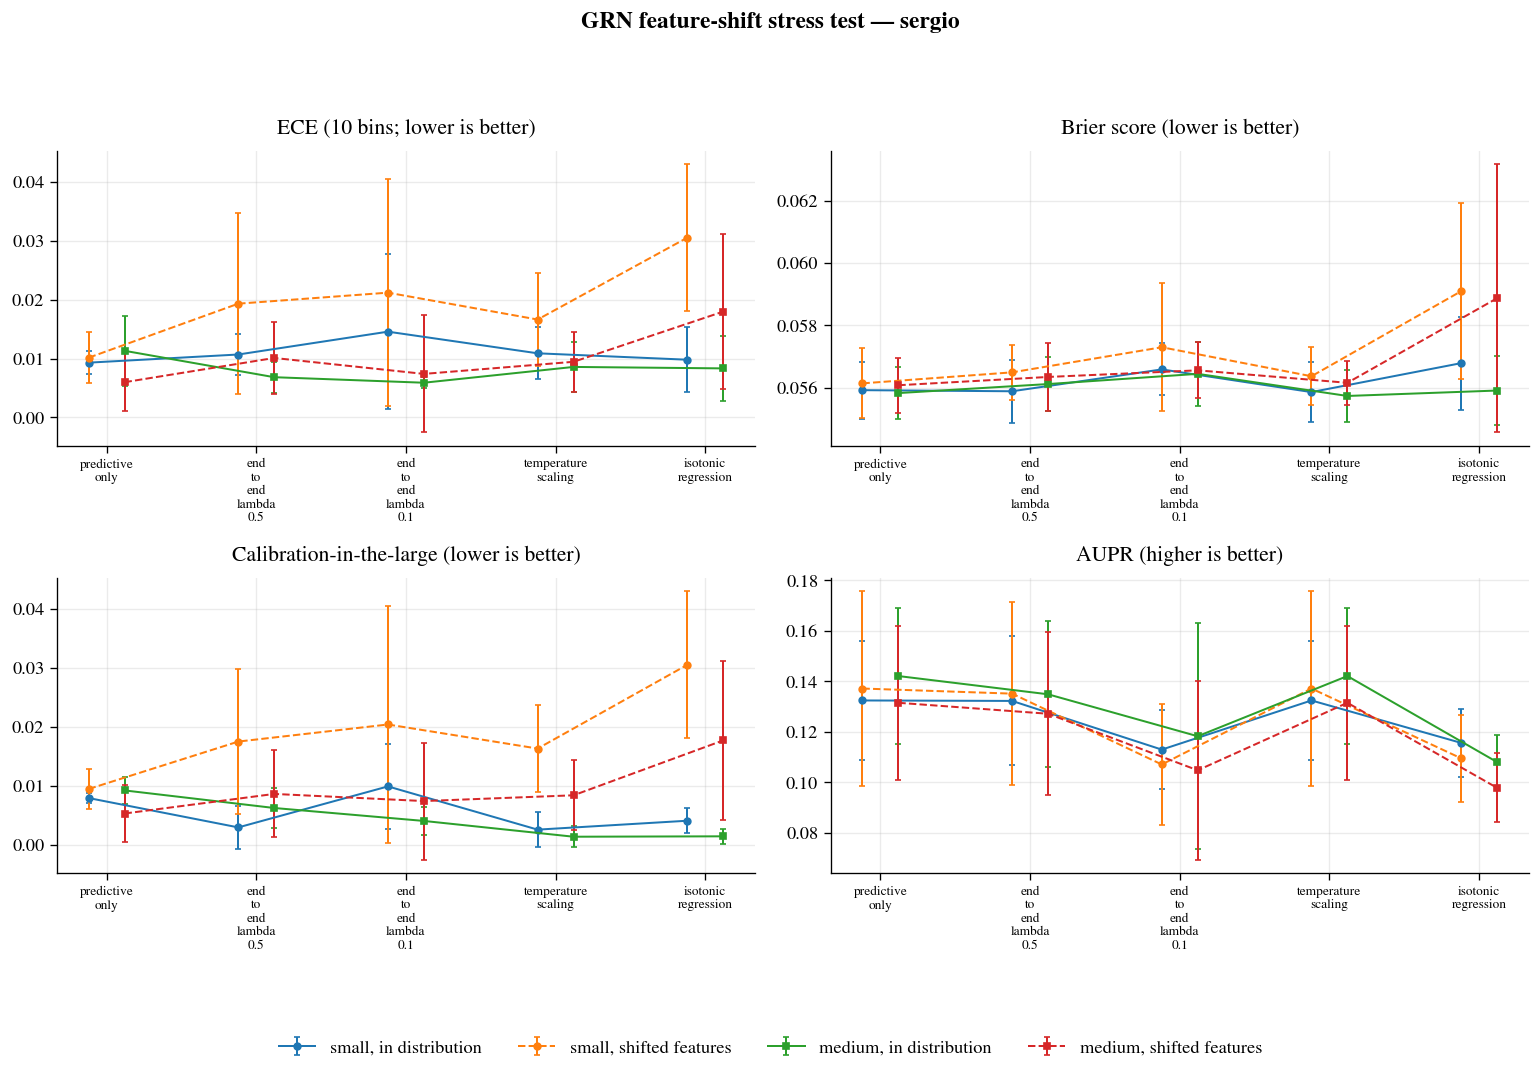

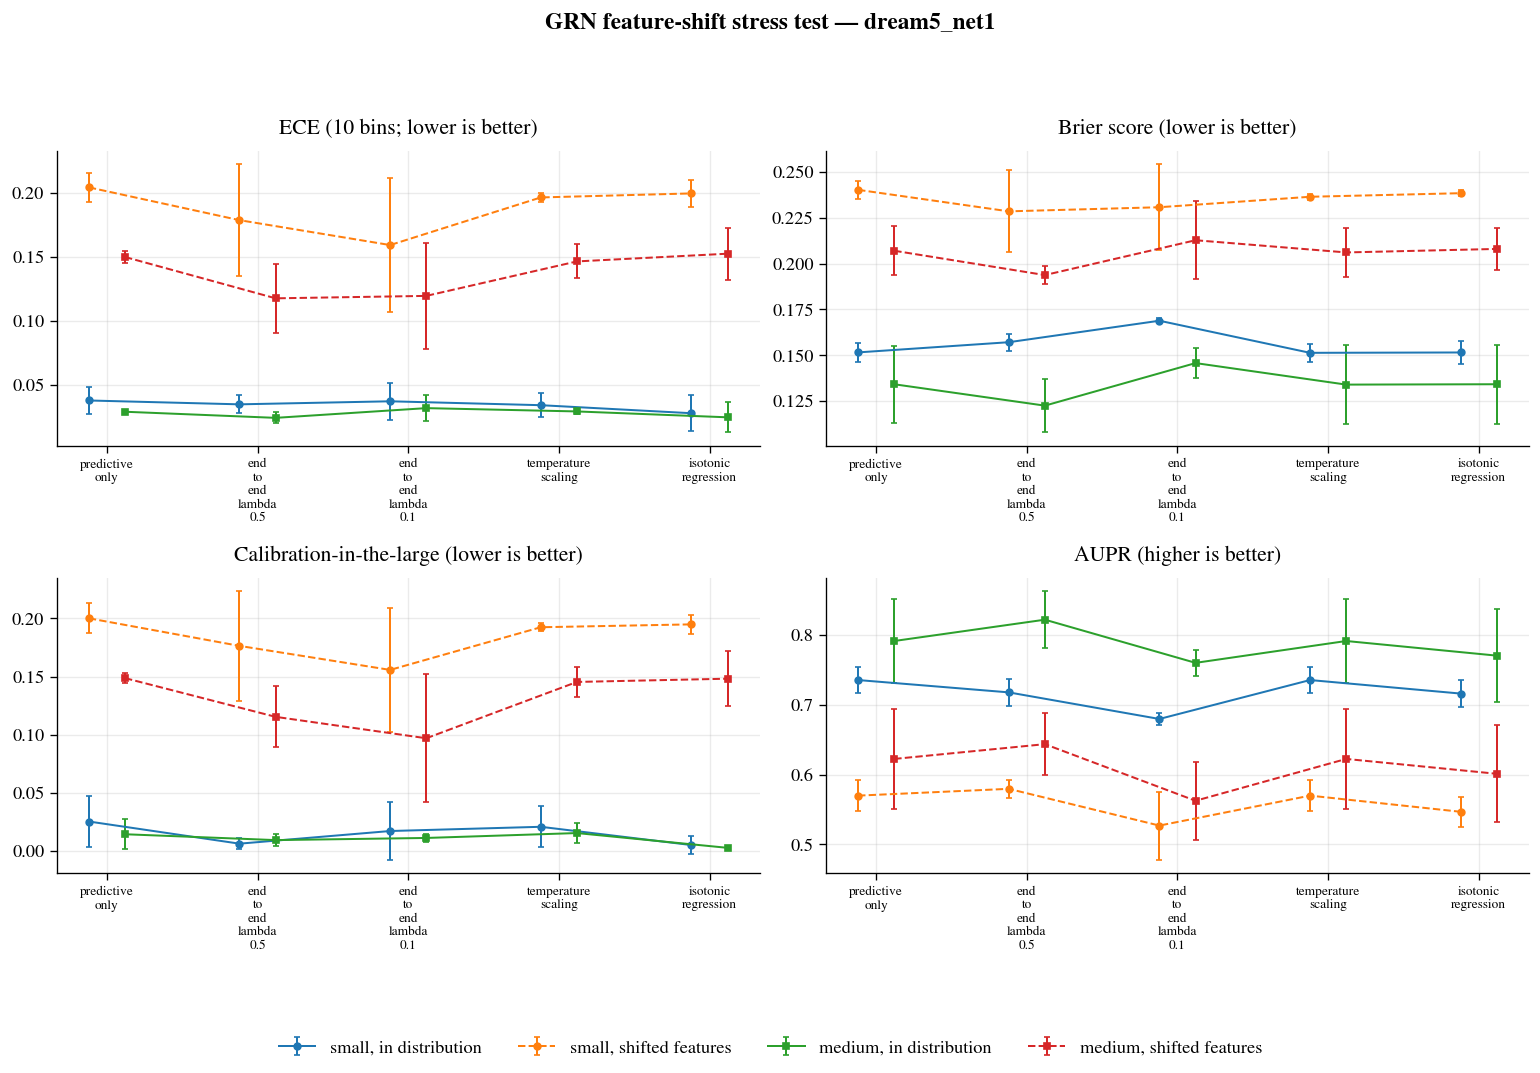

In [4]:
plot_metrics = [
    ("ECE10", "ECE (10 bins; lower is better)"),
    ("Brier", "Brier score (lower is better)"),
    ("calibration_in_large", "Calibration-in-the-large (lower is better)"),
    ("AUPR", "AUPR (higher is better)"),
]
method_order = ["predictive_only", "end_to_end_lambda_0.5", "end_to_end_lambda_0.1",
                "temperature_scaling", "isotonic_regression"]
split_styles = {"in_distribution": "-", "shifted_features": "--"}

for dataset in results_df["dataset"].unique():
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, (metric, title) in zip(axes.ravel(), plot_metrics):
        for architecture in ARCHITECTURES:
            for split in ["in_distribution", "shifted_features"]:
                sub = results_df[(results_df.dataset == dataset) &
                                 (results_df.architecture == architecture) &
                                 (results_df.split == split)]
                g = sub.groupby("method")[metric].agg(["mean", "std"]).reindex(method_order)
                x = np.arange(len(method_order))
                offset = -0.12 if architecture == "small" else 0.12
                ax.errorbar(x + offset, g["mean"], yerr=g["std"],
                            linestyle=split_styles[split], marker="o" if architecture == "small" else "s",
                            capsize=2, linewidth=1.2, markersize=4,
                            label=f"{architecture}, {split.replace('_', ' ')}")
        ax.set_title(title, pad=10)
        ax.set_xticks(np.arange(len(method_order)))
        ax.set_xticklabels([m.replace("_", "\n") for m in method_order], fontsize=8)
        ax.grid(alpha=0.25)
        ax.tick_params(axis="both", which="major", length=4, width=0.8)
    handles, labels = axes[0,0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
    fig.suptitle(f"GRN feature-shift stress test — {dataset}")
    fig.tight_layout(rect=[0, 0.09, 1, 0.94])
    fig.savefig(os.path.join(data_dir, f"Figure_GRN4_CovariateShift_{dataset}.pdf"), bbox_inches="tight")
    plt.show()

## 4. Interpretation and limitations

- This experiment runs on prepared **GRN candidate-pair data**, not the Track 1 synthetic scalar dataset.
- It is a controlled affine expression-feature shift: candidate labels are held fixed while the two expression channels are transformed at test time.
- Because this is a real/simulated GRN edge-prediction dataset without a known posterior, posterior MSE and exact conditional calibration cannot be computed.
- This experiment is a robustness stress test, not proof that real cross-condition or cross-network changes satisfy the pure covariate-shift assumption.
- Results depend on the candidate-pair sampling ratio and ground-truth labels. Do not equate them with official DREAM5 challenge scores unless evaluation protocols match.
- Three seeds are an initial robustness check; increase `SEEDS` for stronger uncertainty estimates.